# Piste 1 : le prétraitement attendu par ResNet50

Même séparation par photo d'origine et même recette que `split_par_photo.ipynb`. Une seule ligne change : `preprocess_input` centre les images sur la moyenne d'ImageNet, comme pendant le pré-entraînement de ResNet50. Le modèle d'origine recevait des pixels bruts de 0 à 255.

Cette piste était annoncée dans la conclusion de `split_par_photo.ipynb` avant d'être lancée. Le jeu de test reste le même et ne sert qu'une fois, à la fin.

In [1]:
import os, re, json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Sequential, layers

dataset_path = "dataset"
seed = 12  # Même graine que le notebook d'origine
batch_size = 16
img_size = (256, 256)
tf.keras.utils.set_random_seed(seed)

## 1. Rattacher chaque variante à sa photo d'origine

In [2]:
AUG = re.compile(r"^aug_(bright|flip|noise|rot|zoom)_")
class_names = sorted(d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d)))

files = []  # (classe, fichier, photo d'origine)
for c in class_names:
    for f in sorted(os.listdir(os.path.join(dataset_path, c))):
        files.append((c, f, AUG.sub("", f)))

originals = {(c, f) for c, f, src in files if f == src}
assert all((c, src) in originals for c, f, src in files), "une variante sans photo d'origine"
print(len(files), "images,", len(originals), "photos d'origine,", len(class_names), "espèces")

1500 images, 250 photos d'origine, 13 espèces


## 2. Regrouper les photos d'origine presque identiques

Le MD5 du notebook de modélisation ne retire que les copies exactes. Une même photo enregistrée en `.jpg` et en `.png`, ou recadrée, passe au travers. On compare une empreinte visuelle (dHash 64 bits) de chaque paire de photos d'origine : à 6 bits d'écart ou moins, elles vont dans le même groupe, donc du même côté de la séparation.

In [3]:
def dhash(path):
    g = np.asarray(Image.open(path).convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

orig = sorted(originals)
hashes = np.array([dhash(os.path.join(dataset_path, c, f)) for c, f in orig])
parent = list(range(len(orig)))
def root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i

pairs = []
for i in range(len(orig)):
    d = (hashes[i + 1:] != hashes[i]).sum(axis=1)
    for j in np.flatnonzero(d <= 6) + i + 1:
        pairs.append((orig[i], orig[j], int(d[j - i - 1])))
        parent[root(j)] = root(i)

for a, b, d in pairs:
    print(f"{d:2d} bits  {a[0]}/{a[1]}  ~  {b[0]}/{b[1]}")
cross = [(a, b) for a, b, _ in pairs if a[0] != b[0]]
print(len(pairs), "paires presque identiques, dont", len(cross), "entre deux espèces différentes")
group = {o: root(i) for i, o in enumerate(orig)}

0 paires presque identiques, dont 0 entre deux espèces différentes


## 3. Séparer par groupe, espèce par espèce

In [4]:
rng = np.random.default_rng(seed)
split = {}
for c in class_names:
    groups = sorted({g for (cc, _), g in group.items() if cc == c})
    rng.shuffle(groups)
    n_test = max(1, round(len(groups) * 0.15))
    n_val = max(1, round(len(groups) * 0.15))
    for k, g in enumerate(groups):
        split.setdefault(g, "test" if k < n_test else "val" if k < n_test + n_val else "train")

sets = {"train": [], "val": [], "test": []}
for c, f, src in files:
    s = split[group[(c, src)]]
    if s == "train" or f == src:  # les variantes augmentées ne vont qu'en entraînement
        sets[s].append((os.path.join(dataset_path, c, f), class_names.index(c)))

# Contrôle : aucun groupe, donc aucune photo d'origine, de part et d'autre de la séparation
grp = {os.path.join(dataset_path, c, f): group[(c, src)] for c, f, src in files}
g = {s: {grp[p] for p, _ in items} for s, items in sets.items()}
assert not (g["train"] & g["val"] or g["train"] & g["test"] or g["val"] & g["test"])
for s, items in sets.items():
    print(f"{s:5s} {len(items):5d} images", np.bincount([y for _, y in items], minlength=len(class_names)))

train  1044 images [ 72  72  96  90  78  42  72  96  96  96  36 102  96]
val      38 images [2 3 4 3 3 2 3 4 3 3 2 3 3]
test     38 images [2 3 4 3 3 2 3 4 3 3 2 3 3]


In [5]:
def load(items):
    # Même redimensionnement que image_dataset_from_directory : bilinéaire, sans recadrage
    x = np.stack([np.asarray(Image.open(p).convert("RGB").resize(img_size, Image.BILINEAR), dtype=np.uint8) for p, _ in items])
    y = tf.keras.utils.to_categorical([lbl for _, lbl in items], len(class_names))
    return x, y

(x_train, y_train), (x_val, y_val), (x_test, y_test) = load(sets["train"]), load(sets["val"]), load(sets["test"])
to_float = lambda x, y: (tf.cast(x, tf.float32), y)  # pixels 0-255 en float, comme image_dataset_from_directory
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(len(x_train), seed=seed).batch(batch_size).map(to_float)
validation_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(batch_size).map(to_float)

## 4. La même architecture que `pretrained_cnn_model.ipynb`, réentraînée

In [6]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.2),
    layers.GaussianNoise(0.05),
])

inputs = Input(shape=(256, 256, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)  # seule différence avec split_par_photo.ipynb
base_model = ResNet50(weights="imagenet", include_top=False, input_tensor=x)
base_model.trainable = False
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
predictions = Dense(len(class_names), activation="softmax")(x)
model = Model(inputs=inputs, outputs=predictions)

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_ds, validation_data=validation_ds, epochs=10, callbacks=[early_stop], verbose=2)

Epoch 1/10


C:\Users\valda\AppData\Local\Temp\claude\C--Users-valda-Documents-code-portfolio\2c638786-8430-4444-a275-1727f13ccc3c\scratchpad\wap-venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 - 185s - 3s/step - accuracy: 0.1552 - loss: 2.6780 - val_accuracy: 0.2368 - val_loss: 2.4488


Epoch 2/10


66/66 - 158s - 2s/step - accuracy: 0.3209 - loss: 2.0216 - val_accuracy: 0.1579 - val_loss: 2.4070


...

66/66 - 111s - 2s/step - accuracy: 0.7079 - loss: 0.8759 - val_accuracy: 0.2895 - val_loss: 3.0896


Epoch 9/10


66/66 - 116s - 2s/step - accuracy: 0.7328 - loss: 0.8644 - val_accuracy: 0.2632 - val_loss: 3.2190


Epoch 10/10


66/66 - 116s - 2s/step - accuracy: 0.7586 - loss: 0.7981 - val_accuracy: 0.2105 - val_loss: 3.1187


In [7]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
history_finetune = model.fit(train_ds, validation_data=validation_ds, epochs=20, callbacks=[early_stop], verbose=2)

Epoch 1/20


66/66 - 196s - 3s/step - accuracy: 0.2883 - loss: 2.1870 - val_accuracy: 0.2368 - val_loss: 2.4208


Epoch 2/20


66/66 - 176s - 3s/step - accuracy: 0.3669 - loss: 1.9226 - val_accuracy: 0.2368 - val_loss: 2.4385


Epoch 3/20


...

66/66 - 172s - 3s/step - accuracy: 0.6485 - loss: 1.1407 - val_accuracy: 0.2368 - val_loss: 2.6214


Epoch 10/20


66/66 - 169s - 3s/step - accuracy: 0.6954 - loss: 1.0428 - val_accuracy: 0.2895 - val_loss: 2.6835


Epoch 11/20


66/66 - 160s - 2s/step - accuracy: 0.7050 - loss: 0.9765 - val_accuracy: 0.2632 - val_loss: 2.7672


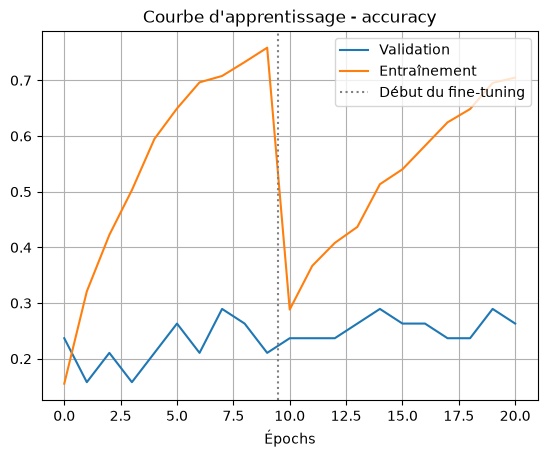

In [8]:
plt.plot(history.history["val_accuracy"] + history_finetune.history["val_accuracy"], label="Validation")
plt.plot(history.history["accuracy"] + history_finetune.history["accuracy"], label="Entraînement")
plt.axvline(len(history.history["accuracy"]) - 0.5, color="grey", ls=":", label="Début du fine-tuning")
plt.title("Courbe d'apprentissage - accuracy"); plt.xlabel("Épochs"); plt.legend(); plt.grid(True); plt.show()

## 5. Évaluation, une seule fois, sur le jeu de test

Le test est petit (une quarantaine de photos) : l'intervalle à 95 % est calculé par bootstrap, 2 000 tirages avec remise.

In [9]:
def evaluate(x, y):
    y_true = y.argmax(axis=1)
    y_pred = model.predict(x.astype("float32"), batch_size=batch_size, verbose=0).argmax(axis=1)
    return y_true, y_pred

def bootstrap(y_true, y_pred, metric, n=2000):
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(y_true), (n, len(y_true)))
    vals = [metric(y_true[i], y_pred[i]) for i in idx]
    return np.percentile(vals, [2.5, 97.5])

macro_f1 = lambda t, p: f1_score(t, p, average="macro", labels=range(len(class_names)), zero_division=0)
results = {}
for name, (x, y) in {"validation": (x_val, y_val), "test": (x_test, y_test)}.items():
    t, p = evaluate(x, y)
    results[name] = dict(n=len(t), accuracy=accuracy_score(t, p), f1_macro=macro_f1(t, p),
                         accuracy_ic95=bootstrap(t, p, accuracy_score).tolist(), f1_macro_ic95=bootstrap(t, p, macro_f1).tolist())
    print(f"{name:10s} n={len(t):3d}  accuracy {results[name]['accuracy']:.3f} {np.round(results[name]['accuracy_ic95'], 3)}"
          f"  F1 macro {results[name]['f1_macro']:.3f} {np.round(results[name]['f1_macro_ic95'], 3)}")
y_true, y_pred = t, p  # test

validation n= 38  accuracy 0.237 [0.105 0.368]  F1 macro 0.221 [0.088 0.291]


test       n= 38  accuracy 0.237 [0.105 0.368]  F1 macro 0.191 [0.072 0.264]


              precision    recall  f1-score   support

      Castor       0.17      1.00      0.29         2
        Chat       0.50      0.33      0.40         3
       Chien       0.00      0.00      0.00         4
      Coyote       0.29      0.67      0.40         3
    Ecureuil       0.00      0.00      0.00         3
       Lapin       0.00      0.00      0.00         2
        Loup       0.00      0.00      0.00         3
        Lynx       0.00      0.00      0.00         4
        Ours       0.00      0.00      0.00         3
        Puma       0.00      0.00      0.00         3
         Rat       1.00      0.50      0.67         2
Raton laveur       0.33      0.33      0.33         3
      Renard       0.29      0.67      0.40         3

    accuracy                           0.24        38
   macro avg       0.20      0.27      0.19        38
weighted avg       0.17      0.24      0.17        38



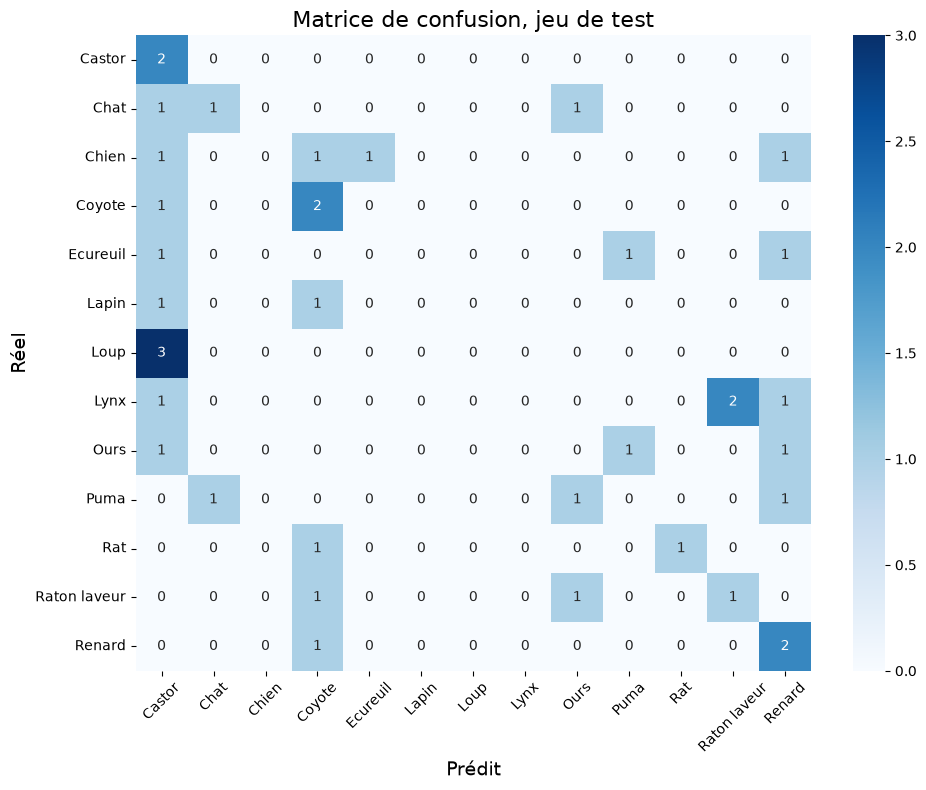

In [10]:
print(classification_report(y_true, y_pred, labels=range(len(class_names)), target_names=class_names, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit", fontsize=14); plt.ylabel("Réel", fontsize=14)
plt.title("Matrice de confusion, jeu de test", fontsize=16)
plt.xticks(rotation=45); plt.yticks(rotation=0); plt.tight_layout(); plt.show()
with open("resultats_split_par_photo_preprocess.json", "w") as f:
    json.dump(results, f, indent=2)

## Conclusion

Sur le même jeu de test (38 photos d'origine) : **24 %** de bonnes réponses (intervalle à 95 % : 11 % à 37 %), F1 macro 0.19 (0.07 à 0.26). Sans le prétraitement, `split_par_photo.ipynb` donnait 26 % (13 % à 39 %). Les intervalles se recouvrent presque entièrement : sur ces données, le prétraitement ne change rien de mesurable.

L'exactitude monte encore vers 70-75 % en entraînement et reste sous 30 % en validation : le modèle retient les photos d'entraînement. Chaque espèce n'a que 6 à 17 photos d'origine pour apprendre. Le premier levier est donc le nombre de photos, pas l'architecture.

Prochaines étapes :
- plus de photos d'origine, au moins une cinquantaine par espèce ;
- une validation croisée par groupes (`StratifiedGroupKFold`) pour une mesure plus stable qu'un test de 38 photos.